Checkpoint #2 

Part a

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

churn = pd.read_csv('netflix_customer_churn.csv')

churn["watch_hours"] = churn["watch_hours"].round().astype(int)
churn = churn[churn["avg_watch_time_per_day"] <= 24]          # impossible values

churn.head()

Part B: Do the customers who churn watch fewer hours of Netflix than those who are still subscribed? 

Subscribed mean: 17.35
Churned mean: 5.91


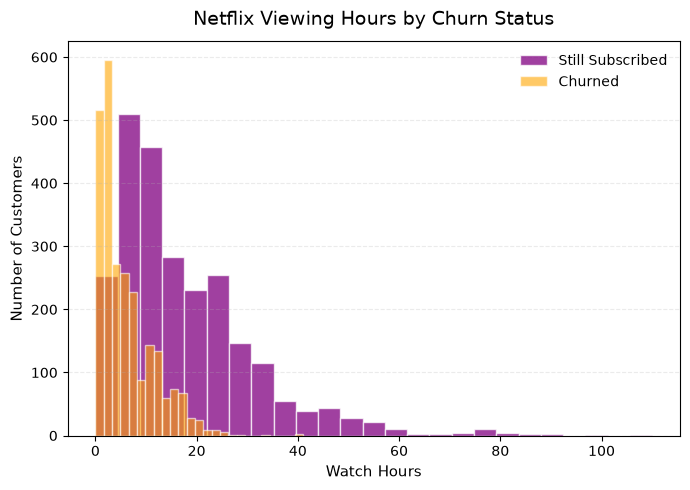

In [4]:
# Separate viewing hours by churn status
subscribed = churn[churn["churned"] == 0]["watch_hours"].dropna()
churned = churn[churn["churned"] == 1]["watch_hours"].dropna()

print("Subscribed mean:", round(subscribed.mean(), 2))
print("Churned mean:", round(churned.mean(), 2))

# Create box plot
plt.figure(figsize=(7, 5))

plt.hist(subscribed, bins=25, alpha=0.75, label="Still Subscribed",
         edgecolor="white", linewidth=1, color="purple")

plt.hist(churned, bins=25, alpha=0.6, label="Churned",
         edgecolor="white", linewidth=1, color="orange")

plt.title("Netflix Viewing Hours by Churn Status", fontsize=14, pad=12)
plt.xlabel("Watch Hours", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [5]:
t_stat, p_value = stats.ttest_ind(churned, subscribed, equal_var=False, alternative="less")

print("t-statistic:", round(t_stat, 4))
print("p-value:", f"{p_value:.2e}")

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is smaller than 0.05. "
        "Therefore, we reject the null hypothesis. There is statistically "
        "significant evidence to say that customers who churn watch fewer hours "
        "of Netflix than customers who remain subscribed.")
else:
    print("Fail to reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is greater than or equal "
        "to 0.05. Therefore, we fail to reject the null hypothesis. "
        "There is insufficient statistical evidence to say that customers who "
        "churn watch fewer hours of Netflix than customers who remain subscribed.")


t-statistic: -38.3832
p-value: 6.20e-266
Reject the null hypothesis.
The hypothesis test produced a t-statistic of -38.3832 and a p-value of 6.20e-266, which is smaller than 0.05. Therefore, we reject the null hypothesis. There is statistically significant evidence to say that customers who churn watch fewer hours of Netflix than customers who remain subscribed.


Part C: Do Basic-plan customers churn more than Standard or Premium customers?

                   Still Subscribed  Churned
subscription_type                           
Basic                           630     1027
Standard                        895      748
Premium                         950      740

Churn rate by plan (%):
subscription_type
Basic       62.0
Standard    45.5
Premium     43.8
Name: churned, dtype: float64


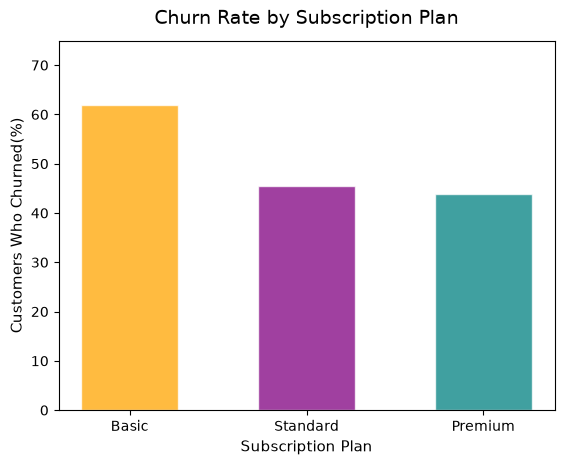


Chi-square statistic: 134.0519
Degrees of freedom: 2
p-value: 7.78e-30
Reject the null hypothesis.
The chi-square test of independence produced a chi-square statistic of 134.0519 with 2 degrees of freedomand a p-value of 7.78e-30, which is smaller than 0.05. Therefore, we reject the null hypothesis. There is statistically significant evidence to say that churn depends on subcription plan. Basic-plan customers churned 62.0%, compared with 45.5% for Standard and 43.8% for Premium.


In [9]:
plan_order = ["Basic", "Standard", "Premium"]

table = (churn.groupby("subscription_type")["churned"]
         .value_counts()
         .unstack()
         .loc[plan_order])
table.columns = ["Still Subscribed", "Churned"]
print(table)

churn_rate = churn.groupby("subscription_type")["churned"].mean().loc[plan_order] * 100
print("\nChurn rate by plan (%):")
print(churn_rate.round(1))

bars = plt.bar(plan_order, churn_rate, width=0.55,
               color=["orange", "purple", "teal"], alpha=0.75,
               edgecolor="white", linewidth=1)

plt.title("Churn Rate by Subscription Plan", fontsize=14, pad=12)
plt.xlabel("Subscription Plan", fontsize=11)
plt.ylabel("Customers Who Churned(%)", fontsize=11)
plt.ylim(0, 75)

plt.show()

chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", f"{p_value:.2e}")

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(
        f"The chi-square test of independence produced a chi-square statistic of "
        f"{chi2:.4f} with {dof} degrees of freedomand a p-value of {p_value:.2e}, "
        "which is smaller than 0.05. Therefore, we reject the null hypothesis. "
        "There is statistically significant evidence to say that churn depends on "
        "subcription plan. Basic-plan customers churned "
        f"{churn_rate['Basic']:.1f}%, compared with {churn_rate['Standard']:.1f}% "
        f"for Standard and {churn_rate['Premium']:.1f}% for Premium.")
else:
    print("Fail to reject the null hypothesis.")
    print(
        f"The chi-square test of independence produced a chi-square statistic of "
        f"{chi2:.4f} with {dof} degrees of freedom and a p-value of {p_value:.2e}, "
        "which is greater than or equal to 0.05. Therefore, we fail to reject the null hypothesis. "
        "There is insufficient statistical evidence to say that churn depends on subscription plan.")



